In [5]:
# Sel 1: setup
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent))

import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src import config as C

RUN = "unet_r34_512_baseline"          # ganti sesuai run yang ingin dilihat
run_dir = C.PROJECT_ROOT / "outputs" / "runs" / RUN
log = pd.read_csv(run_dir / "log.csv")
env = json.loads((run_dir / "env.json").read_text(encoding="utf-8"))
print(json.dumps(env, indent=2))
display(log.tail())

{
  "waktu_mulai": "2026-11-19T13:29:07",
  "python": "3.11.9",
  "torch": "2.11.0+cu128",
  "cuda": "12.8",
  "gpu": "NVIDIA GeForce RTX 3060 Laptop GPU",
  "gpu_memory_gb": 6.0,
  "n_train": 1198,
  "n_val": 171,
  "img_size": 512,
  "mode": "full"
}


,epoch,lr,train_loss,val_loss,detik,gpu_peak_gb,val_miou,val_mdice,val_iou_scab,val_dice_scab,...,val_precision_rot,val_recall_rot,val_iou_greening,val_dice_greening,val_precision_greening,val_recall_greening,val_iou_mechanical_damage,val_dice_mechanical_damage,val_precision_mechanical_damage,val_recall_mechanical_damage
16,17,0.000025,0.556811,0.664179,105.1,1.22,0.309436,0.440563,0.623008,0.767720,...,0.521759,0.344321,0.267447,0.422025,0.287300,0.794676,0.085567,0.157645,0.112490,0.263364
17,18,0.000025,0.545104,0.657930,94.5,1.22,0.309812,0.439817,0.636060,0.777551,...,0.461663,0.401542,0.238751,0.385471,0.263779,0.715608,0.090952,0.166738,0.110244,0.341986
18,19,0.000025,0.540558,0.669585,93.2,1.22,0.297496,0.423727,0.631572,0.774188,...,0.314409,0.419965,0.256317,0.408045,0.282324,0.735623,0.082881,0.153076,0.092333,0.447401
19,20,0.000025,0.540816,0.650463,109.9,1.22,0.318159,0.449263,0.630303,0.773234,...,0.384815,0.401114,0.317219,0.481649,0.353389,0.756054,0.080716,0.149375,0.094520,0.355953
20,21,0.000013,0.526033,0.648281,101.3,1.22,0.332076,0.464710,0.633485,0.775624,...,0.374015,0.398877,0.371134,0.541353,0.444309,0.692637,0.084491,0.155816,0.098163,0.377565


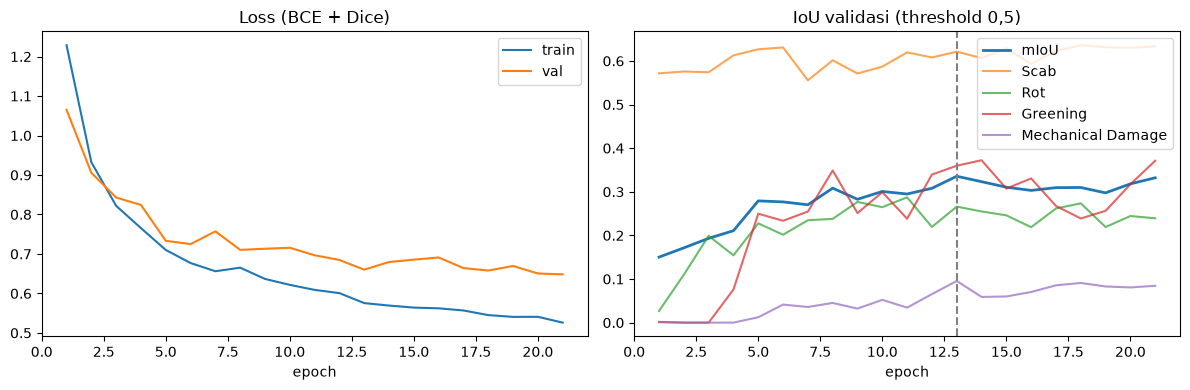

In [6]:
# Sel 2: kurva loss dan val IoU
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(log["epoch"], log["train_loss"], label="train")
axes[0].plot(log["epoch"], log["val_loss"], label="val")
axes[0].set_title("Loss (BCE + Dice)"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(log["epoch"], log["val_miou"], label="mIoU", linewidth=2)
for name in C.CLASS_NAMES:
    key = name.lower().replace(" ", "_")
    axes[1].plot(log["epoch"], log[f"val_iou_{key}"], label=name, alpha=0.7)
axes[1].set_title("IoU validasi (threshold 0,5)"); axes[1].set_xlabel("epoch"); axes[1].legend()
best = log.loc[log["val_miou"].idxmax()]
axes[1].axvline(best["epoch"], color="gray", linestyle="--")
plt.tight_layout()
fig.savefig(run_dir / "kurva_training.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Sel 3: ringkasan epoch terbaik
cols = ["epoch", "val_miou", "val_mdice"] + [
    f"val_iou_{n.lower().replace(' ', '_')}" for n in C.CLASS_NAMES]
display(best[cols].to_frame("epoch terbaik"))
print("GPU puncak (GB):", log["gpu_peak_gb"].max(),
      "| rata-rata detik/epoch:", round(log["detik"].mean(), 1))

,epoch terbaik
epoch,13.000000
val_miou,0.335611
val_mdice,0.472510
val_iou_scab,0.621275
val_iou_rot,0.265939
val_iou_greening,0.359694
val_iou_mechanical_damage,0.095537


GPU puncak (GB): 1.22 | rata-rata detik/epoch: 89.3


In [8]:
keys = [n.lower().replace(' ', '_') for n in C.CLASS_NAMES]
cols = ["epoch", "lr", "val_loss", "val_miou"] + [f"val_{m}_{k}" for k in keys for m in ("precision", "recall")]
display(log[cols].round(3))

,epoch,lr,val_loss,val_miou,val_precision_scab,val_recall_scab,val_precision_rot,val_recall_rot,val_precision_greening,val_recall_greening,val_precision_mechanical_damage,val_recall_mechanical_damage
0,1,0.0,1.065,0.150,0.620,0.879,0.059,0.047,0.006,0.002,0.001,0.004
1,2,0.0,0.906,0.171,0.594,0.950,0.151,0.286,0.000,0.000,0.029,0.000
2,3,0.0,0.843,0.193,0.600,0.929,0.241,0.535,NaN,0.000,0.000,0.000
3,4,0.0,0.824,0.211,0.791,0.731,0.179,0.529,0.081,0.553,1.000,0.000
4,5,0.0,0.733,0.279,0.717,0.833,0.418,0.333,0.296,0.616,0.042,0.017
5,6,0.0,0.725,0.277,0.691,0.879,0.349,0.323,0.272,0.621,0.052,0.165
6,7,0.0,0.757,0.270,0.796,0.648,0.274,0.621,0.302,0.620,0.039,0.320
7,8,0.0,0.710,0.308,0.664,0.865,0.417,0.356,0.478,0.563,0.057,0.182
8,9,0.0,0.713,0.283,0.767,0.691,0.362,0.539,0.284,0.682,0.037,0.198
9,10,0.0,0.716,0.301,0.747,0.732,0.310,0.644,0.346,0.688,0.056,0.433
